## **Praktikum Sistem Komunikasi Multimedia/Sistem dan Teknologi Multimedia**



---



* Nama: Cantika Angela Putri
* NIM: 221331004
* Kelas: 3A TTE


## Modul 4: Move to Front (MTF)
## Bagian Decoder

# Instruksi!

Sebelum melakukan pekerjaan di bawah, ada beberapa hal yang harus diperhatikan.

* Waktu pengerjaan sesuai dengan deadline pada GCR.
* GCR akan ditutup setelah jam tersebut.
* Waktu submit ke GCR berpengaruh pada nilai, lebih cepat akan mendapat nilai tambahan.
* Jika ada kendala saat upload file ipynb, maka bisa dengan menyematkan link google collabnya pada kolom submission tugas di GCR.
* Jika ada pertanyaan bisa diajukan di grup perkuliahan.

*selamat mengerjakan*

### Pendahuluan

Pada modul sebelumnya, kita telah mencoba membuat encoder-decoder kompresi data dengan
menggunakan teknik Run Length Encoding. Pada kali ini, kita akan mencoba membuat encoder-decoder kompresi data yang masih serumpun dengan metode RLE, tetapi dengan detail yang
berbeda, yaitu metode Move to Front. Konsepnya adalah mengupayakan agar simbol-simbol yang
sering muncul ditempatkan pada posisi-posisi awal dengan nomor indeks rendah, sehingga bila
di-encode, cukup menggunakan panjang bit yang sedikit.
Metode ini dimulai dengan sederet simbol dengan posisi setiap simbol direkam dalam indeks. Bila
ada data yang ingin dikirim, maka indeks data tersebut dikirim, dan simbol yang sama pada list
dipindahkan ke posisi terdepan. Begitu seterusnya sampai semua data berhasil dikirim. Sebagai
contoh, bila kita memiliki sederet simbol S = < A, B, C, D, E > dengan indeks posisi I = < 0, 1, 2,
3, 4 >, maka untuk mengirim data D = < D, C, D, E, A, A, B, E, B >, proses yang terjadi dapat
dilihat pada tabel 1.

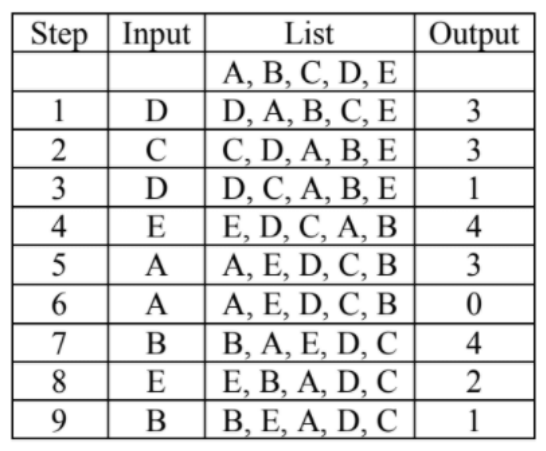

Proses decode nya diawali dengan list yang sama serta menerima input nomor indeks. Dengan
asumsi tidak ada kesalahan pada media transmisi, maka data asalnya dapat direkonstruksi
kembali seperti yang dapat dilihat pada tabel 2.


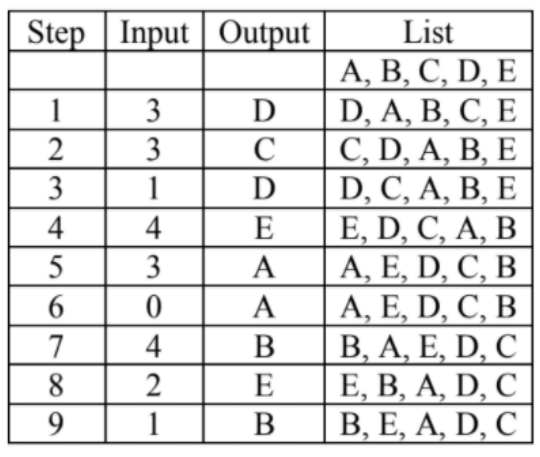

### Langkah-langkah Percobaan

---

Pada bagian decoder, secara garis besar algoritma yang digunakan akan serupa dengan bagian encoder.

 * Seperti sebelumnya program diawali dengan melakukan scan terhadap angka data stream. Pada contoh soal di bawah maka angka pertama yang discan adalah angka 3.

* Kemudian angka 3 tersebut akan dibandingkan dengan deretan simbol dan dicetak simbol yang sesuai index tersebut. Adapun simbol pada index 3 adalah D.

* Lakukan proses MTF pada deretan symbol sehingga menjadi simbol baru

* Ulang proses di atas untuk simbol yang baru (index scan naik).

**Instruksi:**

Sebagai modifikasi dari program Move to Front pendahuluan sebelumnya buatlah program untuk bisa mendeteksi angka urutan pada data input terhadap dictionary yang kita buat (deretan simbol).

Deretan symbol yang digunakan adalah:
S = < A, B, C, D, E >

Sedangkan data stream / data input yang digunakan adalah:
D = < 331430421 >


a. Insertkan flowchartnya pada laman text di bawah.

b. Tuliskan programnya pada laman code di bawah.

Output yang harus dihasilkan dari decoding:

D = < 331430421 >

output = DCDEAABEB

Lalu coba buat program untuk melakukan encoding dan decoding secara berurutan dengan input untuk decoding diambil dari hasil output encoding

In [1]:
#tuliskan program encoder yang telah dibuat di minggu kemarin di sini
dictionary = ['A', 'B', 'C', 'D', 'E'] # Inisialisasi dictionary
datastream = ['D', 'C', 'D', 'E', 'A', 'A', 'B', 'E', 'B'] # Datastream yang akan diproses
output = [] #list untuk menyimpan output

# Proses Move to Front
for char in datastream:
    index = dictionary.index(char)  # Mencari index karakter di dictionary
    output.append(index) # Menambahkan index ke output
    dictionary.insert(0, dictionary.pop(index)) #proses move to front
    print(f"Setelah memproses '{char}', dictionary = {dictionary}") #Mencetak dictionary yang baru setelah Move to Front

print("\nOutput indeks =", output) # Mencetak output indeks
print("Output datastream =", ''.join(datastream)) # Output datastream yang dihasilkan


Setelah memproses 'D', dictionary = ['D', 'A', 'B', 'C', 'E']
Setelah memproses 'C', dictionary = ['C', 'D', 'A', 'B', 'E']
Setelah memproses 'D', dictionary = ['D', 'C', 'A', 'B', 'E']
Setelah memproses 'E', dictionary = ['E', 'D', 'C', 'A', 'B']
Setelah memproses 'A', dictionary = ['A', 'E', 'D', 'C', 'B']
Setelah memproses 'A', dictionary = ['A', 'E', 'D', 'C', 'B']
Setelah memproses 'B', dictionary = ['B', 'A', 'E', 'D', 'C']
Setelah memproses 'E', dictionary = ['E', 'B', 'A', 'D', 'C']
Setelah memproses 'B', dictionary = ['B', 'E', 'A', 'D', 'C']

Output indeks = [3, 3, 1, 4, 3, 0, 4, 2, 1]
Output datastream = DCDEAABEB


In [2]:
#tuliskan program decoder di sini.
#Beri catatan mana bagian,
#1. index scanning
#2. proses perbandingan dengan dictionary/deretan symbol
#3. proses MTF
#4. cetak output
#5. index scanning naik

#tuliskan program decoder di sini.
Dict = ['A', 'B', 'C', 'D', 'E'] # Inisialiasasi nilai Dictionary
output = []  # Variabel untuk menyimpan hasil decoding
encoded_input = [3, 3, 1, 4, 3, 0, 4, 2 , 1]

# 1. Index scanning
for i in range(len(encoded_input)):  # Loop yang akan iterasi untuk setiap angka pada encoded_input
# 2. Proses perbandingan dengan dictionary/deretan simbol
    index = encoded_input[i]  # Mengambil angka di encoded_input sebagai index pada dictionary S
    # Menambahkan simbol yang diambil dari dictionary pada posisi 'index'
    decoded_symbol = Dict[index] #Mencari huruf yang sesuai dengan angka tersebut
    output.append(decoded_symbol)  # Menyimpan simbol hasil decoding ke dalam variabel output
# 3. Proses MTF
    tmp = Dict[index]  # Menyimpan simbol yang baru saja digunakan dalam variabel sementara
    Dict.pop(index)  # Menghapus simbol dari dictionary pada posisi awalnya (index)
    Dict.insert(0, tmp)  # Memindahkan simbol tersebut ke posisi paling depan (Move to Front)
# 4. Mencetak output
print("Decoded output: ",output)  # Mencetak hasil decoding
#print("Decoded output: ", ''.join(output))  # Cetak hasil decoding

# 5. Index scanning naik (proses menuju iterasi berikutnya)

#PENJELASAN BBRP FUNGSI
#tmp
#tmp' adalah variabel sementara (temporary) yang digunakan untuk menyimpan simbol yang baru saja digunakan dalam proses decoding.
#Tujuannya adalah untuk menjaga simbol tersebut agar tidak hilang saat kita mengubah urutan dalam dictionary.

#Dict.pop
#Metode 'pop()' digunakan untuk menghapus dan mengembalikan item dari list pada posisi yang ditentukan (dalam hal ini, 'index').
#Dalam konteks ini, Dict.pop(index) menghapus simbol dari posisi asalnya dalam dictionary.
#Setelah operasi ini, simbol tersebut tidak lagi ada dalam dictionary.

#Dict.insert
#Metode 'insert()' digunakan untuk memasukkan item ke dalam list pada posisi tertentu.
#Dict.insert(0, tmp) memasukkan simbol yang disimpan dalam 'tmp' ke posisi awal (indeks 0) dari dictionary.
#Ini efektif memindahkan simbol yang baru digunakan ke depan list.

Decoded output:  ['D', 'C', 'D', 'E', 'A', 'A', 'B', 'E', 'B']


In [7]:
#tuliskan program gabungan dari encoder dan decoder disini
#------contoh format-------------
#---fungsi untuk encoding---
def mtf_encoding(datastream, dictionary):
    output = []
    for char in datastream:
        index = dictionary.index(char)
        output.append(index)
        dictionary.insert(0, dictionary.pop(index))
    return output
#---fungsi untuk decoding---
def mtf_decoding(encode_input, dictionary):
    output = []
    for index in encode_input:
        decoded_symbol = dictionary[index]
        output.append(decoded_symbol)
        dictionary.insert(0, dictionary.pop(index))
    return ''.join(output)
#---proses utama---
datastream="DCDEEAABEB"
Kamus=['A','B','C','D','E']
#Proses encoding
hasil_encode=mtf_encoding(datastream, Kamus.copy())
#Proses decoding
hasil_decode=mtf_decoding(hasil_encode, Kamus.copy())

print(hasil_encode)
print(hasil_decode)


[3, 3, 1, 4, 0, 3, 0, 4, 2, 1]
DCDEEAABEB



> Analisa dari program di atas (program decode) :

Program decoder ini mengimplementasikan algoritma decoding dengan teknik Move-to-Front (MTF). Strukturnya terdiri dari inisialisasi variabel (dictionary, encoded_input, dan output), loop utama untuk proses decoding, dan output hasil. Inti dari proses program ini adalah proses decoding yang melibatkan index scanning, perbandingan dengan dictionary, dan proses MTF.

Proses decoding dimulai dengan memeriksa setiap angka dalam encoded_input. Setiap angka digunakan sebagai indeks untuk mengambil simbol dari dictionary, yang kemudian disimpan dalam output. Setelah setiap penggunaan simbol, proses MTF diterapkan, memindahkan simbol tersebut ke depan dictionary. Hal ini membantu kompresi data dengan menempatkan simbol yang sering digunakan di posisi depan, meningkatkan efisiensi encoding dan decoding.

Program ini efektif namun memiliki beberapa keterbatasan, yaitu asumsi bahwa encode_input selalu dianggap sesuai dengan Dict dan tidak adanya penanganan error bagi input yang tidak sesuai. Namun, program ini menjelaskan konsep dasar kompresi MTF dan dekompresi data MTF dengan cara yang mudah dipahami.


Lampirkan gambar flowchart di bawah ini:

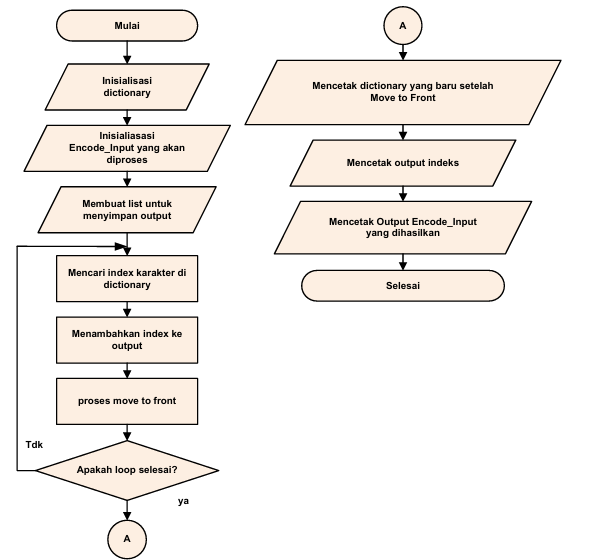



---




© Prof. Hertog Nugroho & Muhammad Yusuf Fadhlan, SST., M.Sc.

Politeknik Negeri Bandung (2023)